##### Import Cell

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import (
    train_test_split,
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import (
    LinearRegression,
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from lightgbm import LGBMRegressor, early_stopping
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import optuna
import shap

In [2]:
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "listings.csv"
df = pd.read_csv(DATA_PATH)
df.head(5)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,23986,https://www.airbnb.com/rooms/23986,20260625152350,2026-06-26,city scrape,""" Characteristic Milanese flat""",I look forward to welcoming you in my flat; it...,NaN,https://a0.muscache.com/pictures/623d63f8-56cf...,95941,...,4.73,4.69,4.46,NaN,NaN,1,1,0,0,0.15
1,40470,https://www.airbnb.com/rooms/40470,20260625152350,2026-06-25,city scrape,Giacinto Cosy & clean flat near MM1,NaN,NaN,https://a0.muscache.com/pictures/891684/01c17b...,174203,...,4.88,4.45,4.52,IT015146C2YDCLSU8G,NaN,2,2,0,0,0.23
2,46536,https://www.airbnb.com/rooms/46536,20260625152350,2026-06-26,city scrape,Nico & Cinzia's Pink Suite!,Over the international fair in April we rent f...,NaN,https://a0.muscache.com/pictures/4eb8e0f5-e17b...,138683,...,4.92,4.36,4.59,IT015209C2BBKGCMT7,NaN,1,1,0,0,0.23
3,538175,https://www.airbnb.com/rooms/538175,20260625152350,2026-06-25,city scrape,Loft with garden on Naviglio Grande,gorgeous loft with garden. Very quiet and comf...,NaN,https://a0.muscache.com/pictures/6527563/6060f...,2643876,...,4.58,4.36,4.25,IT015146C2XCMAQN43,NaN,1,1,0,0,0.07
4,541221,https://www.airbnb.com/rooms/541221,20260625152350,2026-06-26,city scrape,2 rooms apartment in downtown Milan,NaN,NaN,https://a0.muscache.com/pictures/7108899/66d9b...,1442498,...,4.64,4.50,3.93,IT015146C2GRLPV2TY,NaN,1,1,0,0,0.12


## **AirBnb Milan Dataset**

This dataset describes the listing activity and metrics in Milan, Italy for 2021.
I took this dataset from [**Inside AirBnb**](https://insideairbnb.com/) site

## **EDA**

### Deleting null columns

In [3]:
df.info(verbose=True,show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 25750 entries, 0 to 25749
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            25750 non-null  int64  
 1   listing_url                                   25750 non-null  str    
 2   scrape_id                                     25750 non-null  int64  
 3   last_scraped                                  25750 non-null  str    
 4   source                                        25750 non-null  str    
 5   name                                          25750 non-null  str    
 6   description                                   25280 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   25750 non-null  str    
 9   host_id                                       25750 non-null  int64  
 1

**We see that there are a few fully null columns, such as** `neighborhood_overview`, `host_since`, `host_response_time`, **etc. Let's drop them right now, before the preprocessing stage** 

In [4]:
print(df.shape)
df = df.dropna(how='all', axis=1) #Deleted 13 fully empty columns
print(df.shape)

(25750, 90)
(25750, 77)


In [5]:
df.info(verbose=True,show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 25750 entries, 0 to 25749
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            25750 non-null  int64  
 1   listing_url                                   25750 non-null  str    
 2   scrape_id                                     25750 non-null  int64  
 3   last_scraped                                  25750 non-null  str    
 4   source                                        25750 non-null  str    
 5   name                                          25750 non-null  str    
 6   description                                   25280 non-null  str    
 7   picture_url                                   25750 non-null  str    
 8   host_id                                       25750 non-null  int64  
 9   host_url                                      25750 non-null  str    
 1

In [6]:
df.duplicated().sum() #No duplicates found.

np.int64(0)

### Looking at the target value (Price)

In [7]:
df[['price','price_quote_checkin_date','price_quote_checkout_date','price_quote_total_price','price_quote_price_per_night','price_quote_raw']]

,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw
0,$196.81,2026-06-28,2026-07-29,6101.00,196.81,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
1,$137.00,2026-11-01,2026-11-04,411.00,137.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
2,$108.67,2027-01-01,2027-01-04,326.00,108.67,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
3,$130.20,2026-06-26,2026-07-01,651.00,130.20,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
4,$160.00,2026-06-30,2026-07-01,160.00,160.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
...,...,...,...,...,...,...
25745,$120.51,2026-06-26,2026-07-01,602.54,120.51,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
25746,$281.50,2026-06-26,2026-06-28,563.00,281.50,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."
25747,NaN,NaN,NaN,NaN,NaN,NaN
25748,$295.00,2026-06-28,2026-06-30,590.00,295.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""..."


I don't think that these values (every column after price), will be usefull for any kind of analysis, because this is 
1. Post factum data, meaning that you cannot predict the price of the good/service AFTER it was sold/served. (to prevent data leaks)
2. The amount of days stayed does not really influence the price

However, the last column, `price_quote_raw`, is more of an agreggate of what was actually included in price, but it is (in my opinion) has little to no use in my future analysis. So let's just drop them all.
Also, if anyone is assuming that 
`price_quote_price_per_night` is the same as `price`, it is in fact not. `price_quote_price_per_night` shows the total price paid per night, including additional pay. For example cleaning fee, etc.

In [8]:
df.drop(columns = ['price_quote_checkin_date','price_quote_checkout_date','price_quote_total_price','price_quote_price_per_night','price_quote_raw'], inplace=True)

In [9]:
df.shape

(25750, 72)

In [10]:
df['price'].describe()

count       22937
unique       5898
top       $120.00
freq          230
Name: price, dtype: object

`Price` column is object type for some reason, let's change it to int (and to do that let's delete `NaN` entires)

In [11]:
df.dropna(subset='price',inplace=True)
df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

In [12]:
df['price'].describe()

count    22937.000000
mean       187.541264
std        551.346733
min          2.130000
25%        102.750000
50%        136.000000
75%        186.500000
max      55090.000000
Name: price, dtype: float64

In [13]:
df['price'].sort_values(ascending=False).head(30)

4955     55090.00
17124    28587.00
18220    23398.69
25725    16428.00
16831    12889.00
13051    11458.00
2595     10449.25
11723    10039.00
5748      9539.58
12135     9350.00
22974     9301.00
15798     9147.00
17657     8800.00
13072     7817.00
10906     7629.21
10681     6045.00
13929     5762.50
13928     5762.50
10314     5722.50
2754      5530.90
16929     5488.00
12121     5473.03
18115     5181.00
18113     5161.00
18111     5152.50
21199     5032.50
15509     4952.00
13324     4906.50
13930     4906.50
10315     4884.00
Name: price, dtype: float64

We see that there are a few houses that are so expensive, that they will break the histogram plot, and add unnecesary noise to our model in the future. I think that to analyse them correctly, we anyways will need a different model with different weights and so on, so they're harmfull to our model, and our model will not be able to predict this kinds of houses anyways. Let's delete the 1% percentile of the most expensive houses

In [14]:
limit = df['price'].quantile(0.99) 
print(limit) #We'll delete all houses that have daily rent price more than this number
print(df.shape)
df = df[df['price'] <= limit]
print(df.shape) #As we can see, we deleted just a little bit more than a 200 entries and made our model a lot less noisy

1008.0199999999968
(22937, 72)
(22707, 72)


count    22707.000000
mean       160.302663
std        106.468042
min          2.130000
25%        102.500000
50%        135.000000
75%        183.555000
max       1004.500000
Name: price, dtype: float64


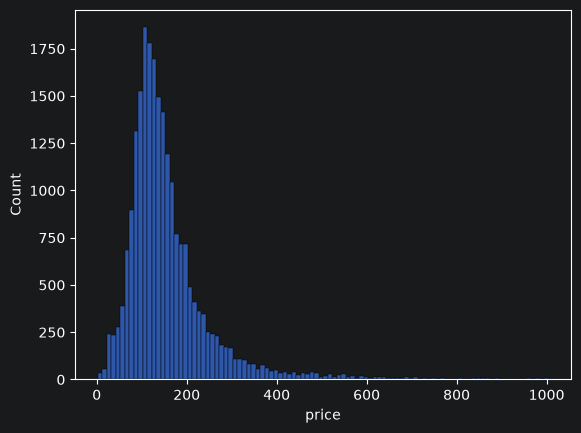

In [15]:
sns.histplot(x=df['price'],bins=100)
print(df['price'].describe())

Distribution is slightly skewed to the right, with mean being moderately (around 18 percent) bigger than the median. I'll probably at least try to use logarithmic scaling when (and if) i will train a linear/KNN models.

Let's now drop useless columns, such as information about scraping etc, and make a primary EDA at the other columns (sanity check and just a basic preprocessing such as changing the column type to correct one)

In [16]:
df.drop(columns=['id','listing_url','scrape_id','last_scraped','source','name','description','picture_url',
                 'host_picture_url','host_profile_url','calendar_last_scraped','license','host_id','host_profile_id','host_url',
                 'host_name', 'host_location','host_about','minimum_minimum_nights', 'maximum_minimum_nights',
                 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'bathrooms',
                 'hosts_time_as_user_years','hosts_time_as_user_months','hosts_time_as_host_months','calculated_host_listings_count_private_rooms',
                 'calculated_host_listings_count_shared_rooms','estimated_occupancy_l365d','estimated_revenue_l365d','has_availability',
                ],
       inplace = True
       )

1.

   `id`, `scrape_id`, `license`: Just the primary keys that carry zero relationship with pricing.

   `listing_url`, `picture_url`, `host_picture_url`, `host_profile_url`:  Simply URLs, no use in predicting the price whatsoever.



3.

`Texthost_id`, `host_profile_id`: Unique host identification numbers. Including them will make the model memorize the hosts, and make it the important part of predicting. For example it just will understand that host number 1 mostly rents out expensive apartments, while host number 2, mostly rents out cheap ones. Also this has to be processed as a really high cardinality categorical data. 
`host_name`, `host_location`: Have no use in prediction. Why would anyone care if the host lives in Netherlands if he rents out the flat in Milan? Also, 99 percent of hosts are still in milan, so this feature has no dispersion, so has a little to no impact anyways. Also this feature has high cardinality too (around 400 categories, even though it could be reduced to just cities in italy and other countries without specifying the cities, still pretty much useless).
`description`, `host_about`: Unstructured, lengthy natural language text. Without applying complex Natural Language Processing (NLP) it's just useless. Also even if it would be applied, almost everything usefull that can be written in description is already written in other data (location, number of rooms, etc.)



5.

`minimum_minimum_nights`, `maximum_minimum_nights`, `minimum_maximum_nights`, `maximum_maximum_nights`, `minimum_nights_avg_ntm`, `maximum_nights_avg_ntm`: Seasonal calendar rules. These variables have extreme multicollinearity with the minimum_nights and maximum_nights. 
`bathrooms`: Has the same information as the `bathrooms_text` but does not show is the bathroom is shared or not. After dividing the `bathrooms_text` into two features (bathroom_count and is_shared), i will delete it too.



7.

`hosts_time_as_user_years`, `hosts_time_as_user_months`, `hosts_time_as_host_months`: keeping `hosts_time_as_host_years` alone is more than enough.
`calculated_host_listings_count_entire_homes`, `calculated_host_listings_count_private_rooms`, `calculated_host_listings_count_shared_rooms`: Too specific. The aggregate calculated_host_listings_count captures whether a host is a commercial operator versus a private owner without over-splitting the feature space.



9.
`estimated_occupancy_l365d`, `estimated_revenue_l365d`: Target leakage. Revenue and occupancy estimates are calculated directly from price  
($\text{Revenue} = \text{Price} \times \text{Booked Nights}$). Including them allows the model to cheat by back-calculating price from the target's. derivative.has_availability: Almost zero dispersion feature. Near 100% of active listings contain the value 't', offering almost no info to the model

### Working with numeric features

array([[<Axes: title={'center': 'hosts_time_as_host_years'}>,
        <Axes: title={'center': 'host_listings_count'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'accommodates'}>],
       [<Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'beds'}>,
        <Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'maximum_nights'}>],
       [<Axes: title={'center': 'availability_30'}>,
        <Axes: title={'center': 'availability_60'}>,
        <Axes: title={'center': 'availability_90'}>,
        <Axes: title={'center': 'availability_365'}>,
        <Axes: title={'center': 'number_of_reviews'}>],
       [<Axes: title={'center': 'number_of_reviews_ltm'}>,
        <Axes: title={'center': 'number_of_reviews_l30d'}>,
        <Axes: title={'center': 'availability_eoy'}>,
        <Axes: title={'center': 'number_of_reviews_ly'}>,
 

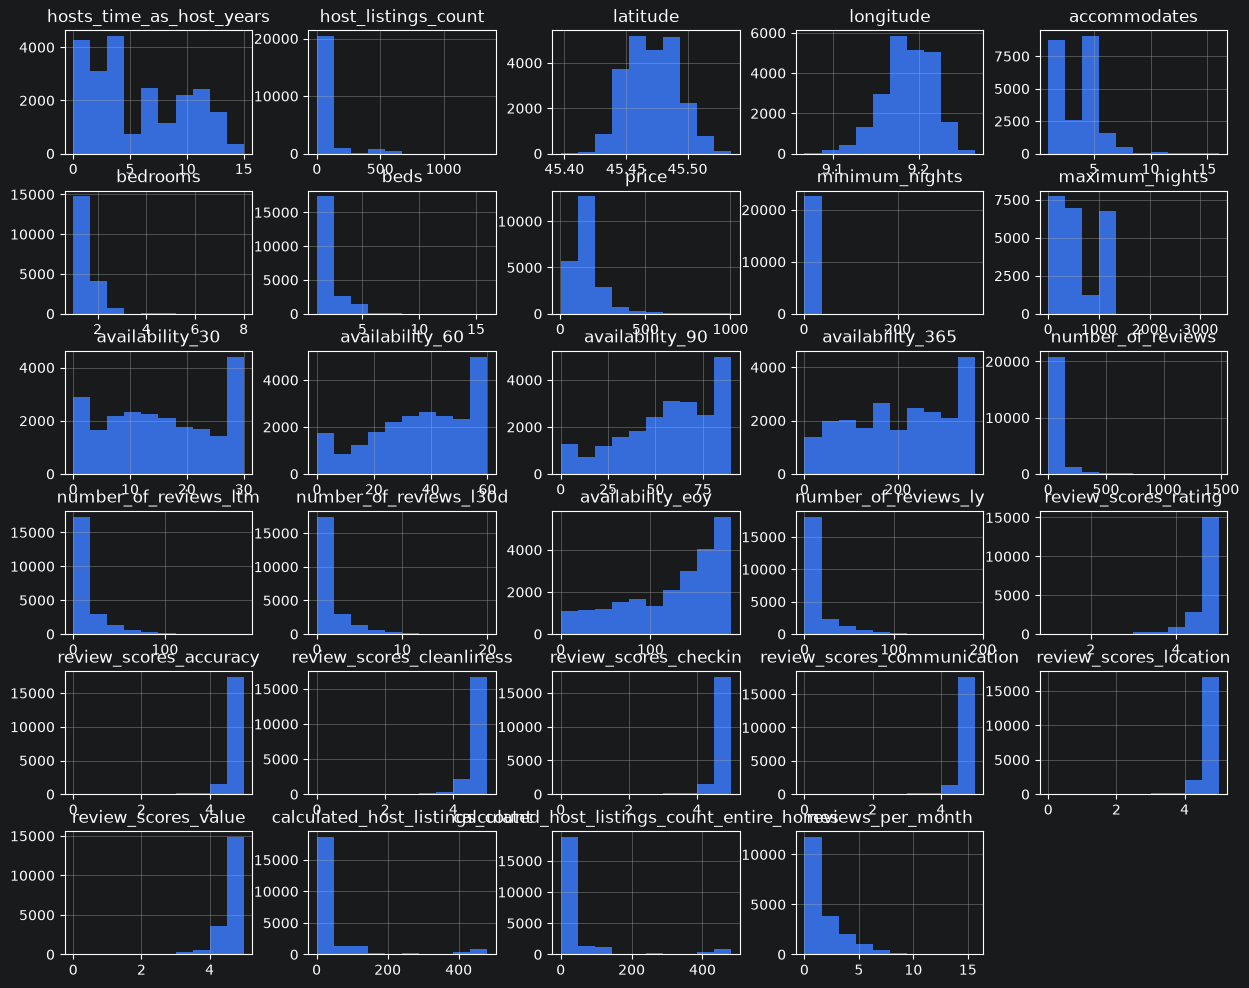

In [17]:
df.hist(figsize=(15,12))

In [18]:
df[['availability_30','availability_60','availability_90','availability_365','availability_eoy']].corr()

,availability_30,availability_60,availability_90,availability_365,availability_eoy
availability_30,1.000000,0.877627,0.786194,0.283627,0.480140
availability_60,0.877627,1.000000,0.940175,0.360309,0.613545
availability_90,0.786194,0.940175,1.000000,0.461318,0.754242
availability_365,0.283627,0.360309,0.461318,1.000000,0.779916
availability_eoy,0.480140,0.613545,0.754242,0.779916,1.000000


I think that `maximum_nights` is little bit unusable in the state that it is in now. If someone is ready to rent out the place for 1000 days (for example), I don't think that on 1001th day he will say "that's it, you've got to leave". And these big numbers really destroy the difference between short and medium term stays (for example between 3 and 14 days). I'll change it to categorical dtype later with three types `short_term`, `medium_term`, and `long_term`. 

Also, I'll aggregate most of the `review_scores` columns into one, since most of the people give reviews "in packs" except for location, which is the only review that does not depend on the host itself. I'll keep location, value, and overall score separated, everything else will be aggregated

Let's delete `availability_60` and `availability_90`, because they correlate with each other and `availability_30` too much. But to keep the info about short term demand, let's keep the 30 day availability. Also `availability_30` does correlate less with `availability_365` than _60 and _90. Also let's delete `availability_eoy`, there is no need for 100500 availability features in our dataset

I'll delete number of reviews in the last 30 days because this column can be too noisy based on the scrape time. If the data is scraped right before the holidays, it's more likely to have more clients and therefore more reviews. And also i will delete number of reviews in the last year, because i already have the number of reviews in the last 12 months. Keeping them both is useless and can harm the model

I'll also delete `neighbourhood_cleansed` because i will use other methods to predict the price by location (probably will look at long,lat)

In [19]:
df.drop(columns=['number_of_reviews_l30d','number_of_reviews_ly','availability_60','availability_90','availability_eoy','neighbourhood_cleansed'],
        inplace=True)

In [20]:
print(df['host_has_profile_pic'].value_counts())
print(df['host_identity_verified'].value_counts())
print(df['host_has_profile_pic'].value_counts())

host_has_profile_pic
t    22117
f      590
Name: count, dtype: int64
host_identity_verified
t    22644
f       63
Name: count, dtype: int64
host_has_profile_pic
t    22117
f      590
Name: count, dtype: int64


### Working with categorical features

In [21]:
df.info()

<class 'pandas.DataFrame'>
Index: 22707 entries, 0 to 25749
Data columns (total 33 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   hosts_time_as_host_years                     22707 non-null  int64  
 1   host_is_superhost                            22707 non-null  str    
 2   host_listings_count                          22707 non-null  int64  
 3   host_has_profile_pic                         22707 non-null  str    
 4   host_identity_verified                       22707 non-null  str    
 5   latitude                                     22707 non-null  float64
 6   longitude                                    22707 non-null  float64
 7   property_type                                22707 non-null  str    
 8   room_type                                    22707 non-null  str    
 9   accommodates                                 22707 non-null  int64  
 10  bathrooms_text

I'll delete `property_type` because there already is an aggregated version of it, called `room_type`  

Also, `amenities` is quite usefull but really hard to process correctly, so i'll use the easiest and yet effective way — count the amount of amenities. The more there are, the better it'll be (most of the time). I also can make top 10 most important amenities and OHE them alone without OHE everything in this column, but no one pays me to do it lol  

I'll delete `last_review` because i don't see its usability, but i'll keep `first_review` because it shows how long this house has been out for rent, the longer it is, the more likely that it is credible and respectable. I'll change it to numeric feature `days_since_first_review` and then delete the original one.

In [22]:
df.drop(columns=['property_type','last_review'],inplace = True)

## **Preprocessing and Feature Engineering**

In [23]:
df['term_of_stay'] = pd.cut(
    df['maximum_nights'],
    bins=[0, 14, 30, np.inf],
    labels=['short_term', 'mid_term', 'long_term'],
)
df.drop(columns = 'maximum_nights',inplace=True)

In [24]:
review_cols = [
    'review_scores_accuracy',
    'review_scores_communication',
    'review_scores_checkin',
    'review_scores_cleanliness',
]
df['review_scores_overall'] = df[review_cols].mean(axis=1)
df.drop(columns=review_cols,inplace=True)

In [25]:
df[['review_scores_overall','review_scores_rating']].corr()

,review_scores_overall,review_scores_rating
review_scores_overall,1.000000,0.891797
review_scores_rating,0.891797,1.000000


Okay, i see that our newly created feature highly correlates with original overall rating. Let's delete our newly created feature (because it's obviously less confident than the original overall value)

In [26]:
df.drop(columns='review_scores_overall',inplace=True)

In [27]:
df['amenities_count'] = df['amenities'].str.count(r'\w+')
df = df.drop(columns=['amenities'])

In [28]:
df['first_review'] = pd.to_datetime(df['first_review'])
df['days_since_first_review'] = (
    pd.Timestamp.now() - df['first_review']
).dt.days
df = df.drop(columns=['first_review'])

In [29]:
df.dropna(axis=0, subset='bathrooms_text',inplace=True)
df.dropna(axis=0, subset='term_of_stay',inplace=True) #There were 12 summary entries with null entries in this two columns. They just itch my eye so i deleted them.

I see that there are around 3k houses without a single review. Let's make a feature that will flag them. 0 means not a single review, 1 means at least 1 review

In [30]:
df['has_reviews'] = (df['days_since_first_review'].notna()).astype(int)

We will now create two different features from `baths_text`: `bathrooms_count` and `bathrooms_type` 

In [31]:
extracted = df["bathrooms_text"].str.extract(
    r"(?P<bathrooms_count>\d+\.?\d*)\s*(?P<bathrooms_type>.*)"
)

df["bathrooms_count"] = pd.to_numeric(
    extracted["bathrooms_count"], errors="coerce"
)
df["bathrooms_type"] = extracted["bathrooms_type"].astype("category")
df[['bathrooms_type']] = df[['bathrooms_type']].replace('baths','bath')
df[['bathrooms_type']] = df[['bathrooms_type']].replace('shared baths','shared bath')
df.drop(columns='bathrooms_text',inplace=True)
df['bathrooms_type'].value_counts()

bathrooms_type
bath            20426
private bath     1135
shared bath      1064
baths               0
shared baths        0
Name: count, dtype: int64

We will now work with our `latitude` and `longitude` features. I thought, which new features would be most utile in this dataset, and came to conclusion that i will create 6 new features. 

1st,2nd,3rd - Distance to Milan's 3 main economic centers - **Duomo di Milano**, **Porta Nuova**, **Milano Centrale**.
4th,5th - 45 degree rotated coordinates for boosting models.
6th - I'll create Kmeans clusters, to make some districts. I'll try different amount of centers, and see which one will divide the map the best

In [32]:
LAT_TO_KM = 111.0
LON_TO_KM = 111.0 * np.cos(np.radians(45.46)) #Because milan is at 45.46 latitude

#I will use Manhatann distance, because in cities you don't move in diagonals, but in straight lines most of the time.
df['dist_duomo'] = abs(df['latitude'] - 45.4641) * LAT_TO_KM + abs(df['longitude'] - 9.1919) * LON_TO_KM
df['dist_porta_nuova'] = abs(df['latitude'] - 45.4839) * LAT_TO_KM + abs(df['longitude'] - 9.1896) * LON_TO_KM
df['dist_station'] = abs(df['latitude'] - 45.4853) * LAT_TO_KM + abs(df['longitude'] - 9.2045) * LON_TO_KM
df['coord_rot45_x'] = df['latitude'] + df['longitude']
df['coord_rot45_y'] = df['latitude'] - df['longitude']
kmeans = KMeans(n_clusters=12, random_state=0,) #I checked a lot of "n_clusters", but deleted the part where i checked it. 12 seemed the best solution. 
                                                #The elbow method showed me that the best amount of clusters is 5, but by eyes showed me that 12 clusters
                                                #divide the map in the more informative way.
df['lat_to_km'] = df['latitude'] * LAT_TO_KM
df['lon_to_km'] = df['longitude'] * LON_TO_KM
df.drop(columns=['latitude','longitude'],inplace=True)
df['geo_cluster'] = kmeans.fit_predict(df[['lat_to_km', 'lon_to_km']])
df['geo_cluster'] = df['geo_cluster'].astype('category')

Just a little bit more of data cleaning and manipulation

In [33]:
df['host_is_superhost'] = df['host_is_superhost'].replace('t',1).replace('f',0)
df.drop(columns=['host_has_profile_pic','host_identity_verified'],inplace=True) #I deleted these beacause it was quasi constant, meaning that as low as 2 percent of the values were different from the dominant uniform type

Let's now arrange our on numeric/categorical basis

In [34]:
numerical_features = [
    "hosts_time_as_host_years",
    "host_listings_count",
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "availability_30",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "review_scores_rating",
    "review_scores_location",
    "review_scores_value",
    "calculated_host_listings_count",
    "calculated_host_listings_count_entire_homes",
    "reviews_per_month",
    "amenities_count",
    "days_since_first_review",
    "has_reviews",
    "bathrooms_count",
    'dist_duomo',
    'dist_porta_nuova',
    'dist_station',
    'coord_rot45_x',
    'coord_rot45_y',
]

categorical_features = [
    "host_is_superhost",
    "room_type",
    "term_of_stay",
    "bathrooms_type",
    "geo_cluster"
]

In [35]:
df[numerical_features] = df[numerical_features].astype('float')
df[categorical_features] = df[categorical_features].astype('category')

And now let's make our `train_test_split`

In [36]:
X = df.drop(columns='price')
y = df.price
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.8,random_state=0)

Let's now fill our missing data (Of course we'll train it on train data to avoid data leakage)

In [37]:
SI = SimpleImputer(strategy='most_frequent')
SI.fit(X_train) 
X_train = pd.DataFrame(SI.transform(X_train),columns=X_train.columns)
X_test = pd.DataFrame(SI.transform(X_test),columns=X_test.columns)

Now we will use `OneHotEncoder` on our data

In [38]:
OHE = OneHotEncoder(drop="if_binary",sparse_output=False)
OHE.fit(X_train[categorical_features])
X_train = pd.concat([pd.DataFrame(OHE.transform(X_train[categorical_features]), columns=OHE.get_feature_names_out(categorical_features), index=X_train.index), X_train], axis=1).drop(columns=categorical_features)
X_test = pd.concat([pd.DataFrame(OHE.transform(X_test[categorical_features]), columns=OHE.get_feature_names_out(categorical_features), index=X_test.index), X_test], axis=1).drop(columns=categorical_features)

In [39]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

In [40]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 18156 entries, 0 to 18155
Data columns (total 50 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   host_is_superhost_1                          18156 non-null  float32
 1   room_type_Entire home/apt                    18156 non-null  float32
 2   room_type_Hotel room                         18156 non-null  float32
 3   room_type_Private room                       18156 non-null  float32
 4   room_type_Shared room                        18156 non-null  float32
 5   term_of_stay_long_term                       18156 non-null  float32
 6   term_of_stay_mid_term                        18156 non-null  float32
 7   term_of_stay_short_term                      18156 non-null  float32
 8   bathrooms_type_bath                          18156 non-null  float32
 9   bathrooms_type_private bath                  18156 non-null  float32
 10  bathrooms

## **Modeling And Experiments**

First of all, I'll create `evaluate_regression` function to evaluate all of our models with most important and classic metrics for regression:  
`R^2`,  
`MAE`,  
`RMSE`,  
`MSE`,  
`MAPE`

In [41]:
def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    print(f"R²: {r2:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MSE: {mse:.4f}")
    
    #Checking if any y is equal to 0, because in that case MAPE will give out inadequate numbers
    if np.any(y_true == 0):
        pass
    else:
        mape = mean_absolute_percentage_error(y_true, y_pred)
        print(f"MAPE: {mape * 100:.2f}%")
        

Let's first make our `DummyRegressor` as a baseline model

In [42]:
dummy = DummyRegressor(strategy='median')
dummy.fit(X_train,y_train)
y_pred_dummy = dummy.predict(X_test)
evaluate_regression(y_test,y_pred_dummy)

R²: -0.0529
MAE: 61.3929
RMSE: 103.8583
MSE: 10786.5451
MAPE: 44.93%


##### Let's now check some basic untuned (or little tuned) models, to pick the best ones from them

**Linear Regression**

In [43]:
linreg = LinearRegression()
linreg.fit(X_train,y_train)
y_pred_linreg = linreg.predict(X_test)
evaluate_regression(y_test,y_pred_linreg)

R²: 0.3267
MAE: 50.4394
RMSE: 83.0510
MSE: 6897.4651
MAPE: 36.11%


**Decision Tree**

In [44]:
dectree = DecisionTreeRegressor(random_state=0)
dectree.fit(X_train,y_train)
y_pred_dectree = dectree.predict(X_test)
evaluate_regression(y_test,y_pred_dectree)

R²: -0.2104
MAE: 62.8323
RMSE: 111.3563
MSE: 12400.2158
MAPE: 43.13%


**Random Forest**

In [45]:
randfor = RandomForestRegressor(random_state=0,n_estimators=300,n_jobs=-1)
randfor.fit(X_train,y_train)
y_pred_randfor = randfor.predict(X_test)
evaluate_regression(y_test,y_pred_randfor)

R²: 0.4441
MAE: 44.1816
RMSE: 75.4627
MSE: 5694.6154
MAPE: 32.83%


**Gradient Boosting**

In [46]:
gradboost = GradientBoostingRegressor(random_state=0,max_depth=4,n_estimators=1000,n_iter_no_change=50)
gradboost.fit(X_train,y_train)
y_pred_gradboost = gradboost.predict(X_test)
evaluate_regression(y_test,y_pred_gradboost)

R²: 0.4486
MAE: 43.4814
RMSE: 75.1582
MSE: 5648.7545
MAPE: 30.51%


**XGBoost**

In [47]:
xgb = XGBRegressor(max_depth = 4,random_state=0,n_estimators=2000)
xgb.fit(X_train,y_train)
y_pred_xgb = xgb.predict(X_test)
evaluate_regression(y_test,y_pred_xgb)

R²: 0.4104
MAE: 47.0717
RMSE: 77.7169
MSE: 6039.9216
MAPE: 34.14%


**LightGBM**

In [48]:
lgb = LGBMRegressor(random_state=0,verbose=0,n_estimators=2000)
lgb.fit(X_train, y_train)
y_pred_lgb = lgb.predict(X_test)
evaluate_regression(y_test, y_pred_lgb)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
R²: 0.4462
MAE: 44.0614
RMSE: 75.3244
MSE: 5673.7689
MAPE: 30.80%


**CatBoost**

In [49]:
cb = CatBoostRegressor(random_state=0,verbose=0)
cb.fit(X_train, y_train)
y_pred_cb = cb.predict(X_test)
evaluate_regression(y_test, y_pred_cb)

R²: 0.4971
MAE: 41.4295
RMSE: 71.7772
MSE: 5151.9654
MAPE: 29.01%


After we've trained all of the basic models, let's take the best one out of them, and see importances of each feature using SHAP (SHapley Additive exPlanations), and also by using `feature_importances`

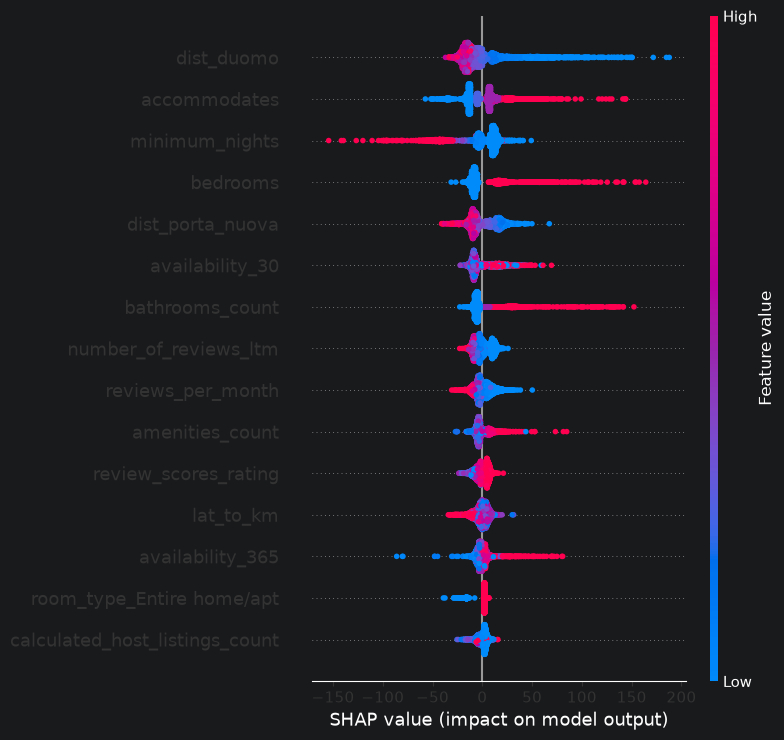

In [50]:
explainer = shap.TreeExplainer(cb)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test, max_display=15)

In [51]:
pd.DataFrame(data=cb.feature_importances_,index=cb.feature_names_).sort_values(0,ascending=False).head(20)

,0
dist_duomo,11.112448
bedrooms,8.899749
bathrooms_count,7.231720
minimum_nights,6.820623
accommodates,6.632157
availability_30,6.241242
availability_365,4.976178
amenities_count,4.239050
dist_porta_nuova,3.870934
reviews_per_month,3.859366


We can see that in both evaluation types, the distance to Duomo (`dist_duomo`) is the main factor in price forming. The rest of the list is pretty similiar too in most cases.

Even though `CatBoost` showed us the best results "from the box", it's less influenced by hyperparameter tuning. So after basic evaluation and checking on feature importances, we will now tune `LightGBM` and `XGBoost`.

##### **LightGBM**

In [52]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective_lgbm(trial):
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)
    params = {
        'objective': 'regression', 
        'metric': 'rmse',          
        'verbosity': -1,             
        'random_state': 0,
        'n_estimators': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0)
    }

    model = LGBMRegressor(**params)
    model.fit(
        X_tr, y_tr,
        eval_X= X_val,
        eval_y=y_val,
        callbacks=[
            early_stopping(stopping_rounds=50, verbose=False)
        ]
    )
    preds = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    return rmse

In [53]:
study_lgbm = optuna.create_study(direction='minimize', study_name="lgbm_regression_study")
study_lgbm.optimize(objective_lgbm, n_trials=50,show_progress_bar=False)

In [54]:
best_params_lgbm = study_lgbm.best_params

best_params_lgbm['random_state'] = 0
best_params_lgbm['verbosity'] = -1
best_params_lgbm['n_estimators'] = 2500


lgbm_tuned = LGBMRegressor(**best_params_lgbm)

lgbm_tuned.fit(X_train, y_train)

,num_leaves,258
,max_depth,11
,learning_rate,0.01228028787589287
,n_estimators,2500
,min_child_samples,45
,subsample,0.9163608835487814
,colsample_bytree,0.6095277759084318
,random_state,0
,verbosity,-1
,boosting_type,'gbdt'
,subsample_for_bin,200000


In [55]:
y_pred_lgbm_tuned = lgbm_tuned.predict(X_test)
evaluate_regression(y_test, y_pred_lgbm_tuned)

R²: 0.4780
MAE: 41.7825
RMSE: 73.1271
MSE: 5347.5733
MAPE: 29.00%


##### **XGBoost**

In [56]:
def objective_xgboost(trial):
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",  
        "tree_method": "hist",
        "random_state": 0,
        "n_jobs": 4,
        "n_estimators": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "gamma": trial.suggest_float("gamma", 1e-8, 5.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }
    model = XGBRegressor(**params, early_stopping_rounds=50)
    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose = 0
    )
    preds = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    return rmse

In [57]:
study_xgboost = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(n_startup_trials=10, seed=0),study_name="xgboost_regression_study")
study_xgboost.optimize(objective_xgboost, n_trials=50,show_progress_bar=False,n_jobs=4)

In [58]:
best_params_xgboost = study_xgboost.best_params


best_params_xgboost['random_state'] = 0
best_params_xgboost['verbosity'] = 0
best_params_xgboost['n_estimators'] = 2500

xgboost_tuned = XGBRegressor(**best_params_xgboost)

xgboost_tuned.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.4025035650475912
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [59]:
y_pred_xgboost_tuned = xgboost_tuned.predict(X_test)
evaluate_regression(y_test, y_pred_xgboost_tuned)

R²: 0.4836
MAE: 41.6980
RMSE: 72.7358
MSE: 5290.5037
MAPE: 28.77%


##### **CatBoost**

In [60]:
def objective_catboost(trial):
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)
    
    params = {
        "loss_function": "RMSE",
        "eval_metric": "RMSE",
        "random_seed": 0,
        "thread_count": 4, 
        "iterations": 2000, 
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "depth": trial.suggest_int("depth", 3, 10), 
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-8, 10.0, log=True), 
        "random_strength": trial.suggest_float("random_strength", 1e-8, 10.0, log=True), 
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 1.0), 
        "border_count": trial.suggest_int("border_count", 32, 255) 
    }
    
   
    model = CatBoostRegressor(**params, early_stopping_rounds=50)
    
    
    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose=0 
    )
    
    
    preds = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    return rmse

In [61]:
study_catboost = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(n_startup_trials=10, seed=0), study_name="catboost_regression_study")
study_catboost.optimize(objective_catboost, n_trials=50, show_progress_bar=False, n_jobs=4)

In [62]:
best_params_catboost = study_catboost.best_params

best_params_catboost['random_seed'] = 0
best_params_catboost['verbose'] = 0
best_params_catboost['iterations'] = 2000
best_params_catboost['thread_count'] = 4

catboost_tuned = CatBoostRegressor(**best_params_catboost)
catboost_tuned.fit(X_train, y_train)

CatBoostRegressor(bagging_temperature=0.9780520876758249, border_count=170, depth=6, iterations=2000, l2_leaf_reg=0.008722514646576026, learning_rate=0.02948757235615703, loss_function='RMSE', random_seed=0, random_strength=4.6363056959330955e-07, thread_count=4, verbose=0)

In [63]:
y_pred_catboost_tuned = catboost_tuned.predict(X_test)
evaluate_regression(y_test, y_pred_catboost_tuned)

R²: 0.4891
MAE: 41.5032
RMSE: 72.3474
MSE: 5234.1458
MAPE: 28.89%


### **Creating an ansamble**

After tuning our 3 models with Optuna, we unfortunately see that out-of-the-box catboost beats them all. However, instead of just taking it and moving on, I will make a more stable, ansamble model, out of **tuned** `XGBoost` and `LightGBM`, and also out of **untuned** `CatBoost` models. Because they use different tree creating architecture (depthwise vs leafwise vs symmetrical), their blend will make the prediction more stable.  

I won't use anything too complex, just simply will blend their votes with a dominant weight on `Catboost` because it did a better job in predicting

In [64]:
preds_xgb = xgboost_tuned.predict(X_test)
preds_lgb = lgbm_tuned.predict(X_test)
preds_cat = cb.predict(X_test)
weights = [0.15, 0.15, 0.7]
final_weighted = (
    weights[0] * preds_xgb + weights[1] * preds_lgb + weights[2] * preds_cat
)
evaluate_regression(y_test, final_weighted)

R²: 0.5010
MAE: 40.8709
RMSE: 71.4976
MSE: 5111.9061
MAPE: 28.38%


As we can see, the ensemble of three models yielded a higher $R^2$ than any of the individual models, although by a small margin.

The project is structured as a reproducible production pipeline. Feature preprocessing, ensemble training with model serialization, and batch inference scripts are organized into `src/preprocess.py`, `src/train.py`, and `src/predict.py`. Execution instructions are provided in README.md